In [55]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import (
    root_mean_squared_error,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier

# Configure display and plotting settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

In [56]:
df_tracks = pd.read_csv("data/spotify_tracks.csv")
df_market = pd.read_csv("data/featured_Spotify_track_info.csv")
print(f"Primary Tracks shape: {df_tracks.shape}")
print(f"Market Drivers shape: {df_market.shape}")

Primary Tracks shape: (114000, 21)
Market Drivers shape: (20251, 13)


In [57]:
primary_artist_col = 'artists' if 'artists' in df_tracks.columns else 'artist_name'
df_tracks['artist_key'] = df_tracks[primary_artist_col].astype(str).str.lower().str.strip()
df_market['artist_key'] = df_market['names'].astype(str).str.lower().str.strip()
df_market_unique = df_market.drop_duplicates(subset=['artist_key'])
df_merged = pd.merge(
    df_tracks, 
    df_market_unique[['artist_key', 'followers', 'monthly_listeners', 'playlists_found', 'popularity']], 
    on='artist_key', 
    how='left',
    suffixes=('', '_market')
)

In [58]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 26 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         114000 non-null  int64  
 1   track_id           114000 non-null  object 
 2   artists            113999 non-null  object 
 3   album_name         113999 non-null  object 
 4   track_name         113999 non-null  object 
 5   popularity         114000 non-null  int64  
 6   duration_ms        114000 non-null  int64  
 7   explicit           114000 non-null  bool   
 8   danceability       114000 non-null  float64
 9   energy             114000 non-null  float64
 10  key                114000 non-null  int64  
 11  loudness           114000 non-null  float64
 12  mode               114000 non-null  int64  
 13  speechiness        114000 non-null  float64
 14  acousticness       114000 non-null  float64
 15  instrumentalness   114000 non-null  float64
 16  li

In [59]:
df_merged['has_market_data'] = (df_merged['followers'] > 0).astype(int)
df_merged['followers'] = df_merged['followers'].fillna(0)
df_merged['monthly_listeners'] = df_merged['monthly_listeners'].fillna(0)
df_merged['playlists_found'] = df_merged['playlists_found'].fillna(0)

df_merged['major_label'] = (df_merged['followers'] > 1000000).astype(int)
df = df_merged
df_unseen = df
print(f"Successfully merged dataset shape: {df.shape}")

# Verify match rate and show summary
matched_count = (df['has_market_data'] == 1).sum()
total_tracks = len(df)
match_percentage = (matched_count / total_tracks) * 100

print("=" * 50)
print("Market Data Match Rate Summary")
print("=" * 50)
print(f"Total tracks in primary dataset: {total_tracks}")
print(f"Tracks with real market data: {matched_count} ({match_percentage:.2f}%)")
print(f"Tracks defaulting to imputed 0: {total_tracks - matched_count}")

Successfully merged dataset shape: (114000, 28)
Market Data Match Rate Summary
Total tracks in primary dataset: 114000
Tracks with real market data: 20437 (17.93%)
Tracks defaulting to imputed 0: 93563


In [60]:
target_col = 'popularity_y' if 'popularity_y' in df.columns else 'popularity'
df['target'] = (pd.to_numeric(df[target_col], errors='coerce') >= 50).astype(int)
df['duration_bucket'] = pd.cut(df['duration_ms'], bins=[0, 120000, 240000, np.inf], labels=['short', 'medium', 'long']).astype(str)
df['acoustic_energy_ratio'] = df['acousticness'] / (df['energy'] + 1e-5)

extended_features = [
    # Audio & Structural Features
    'track_genre', 'explicit', 'key', 'mode', 'time_signature', 
    'duration_ms', 'energy', 'speechiness', 'acousticness', 
    'instrumentalness', 'liveness', 'valence', 'tempo',
    'danceability', 'loudness',
    # Market Drivers & Structural Flag
    'followers', 'monthly_listeners', 'playlists_found', 'major_label', 'has_market_data',
    # Engineered Features
    'duration_bucket', 'acoustic_energy_ratio'
]
print(f"Total features configured for model pipeline: {len(extended_features)}")

Total features configured for model pipeline: 22


In [61]:
target_col = 'popularity_y' if 'popularity_y' in df.columns else 'popularity'
df['target'] = (pd.to_numeric(df[target_col], errors='coerce') >= 50).astype(int)
df['duration_bucket'] = pd.cut(df['duration_ms'], bins=[0, 120000, 240000, np.inf], labels=['short', 'medium', 'long']).astype(str)
df['acoustic_energy_ratio'] = df['acousticness'] / (df['energy'] + 1e-5)
extended_features = [
    # Track acoustic qualities
    'track_genre', 'explicit', 'key', 'mode', 'time_signature', 
    'duration_ms', 'energy', 'speechiness', 'acousticness', 
    'instrumentalness', 'liveness', 'valence', 'tempo',
    'danceability', 'loudness',
    # Playlist exposure and flag
    'followers', 'monthly_listeners', 'playlists_found', 'major_label', 'has_market_data',
    # Extra engineered Features
    'duration_bucket', 'acoustic_energy_ratio'
]

print(f"Total features configured for model pipeline: {len(extended_features)}")

Total features configured for model pipeline: 22


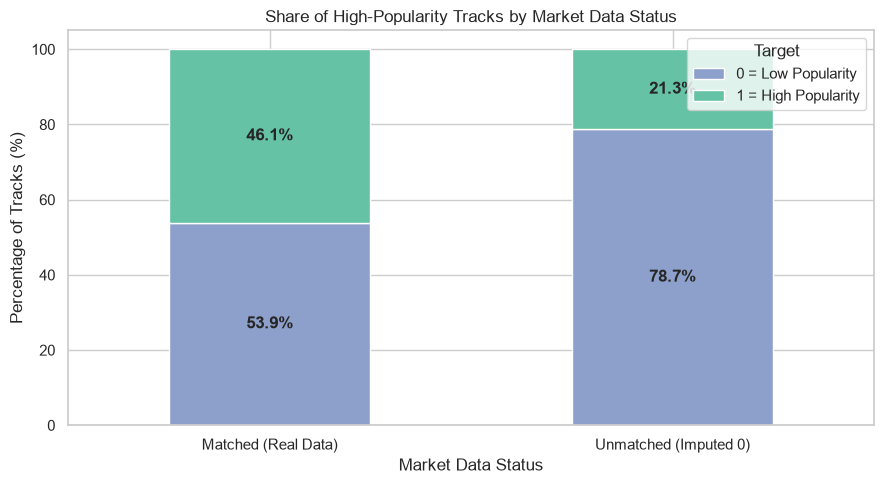

In [62]:
# EDA analysis
df['market_status_label'] = df['has_market_data'].map({1: 'Matched (Real Data)', 0: 'Unmatched (Imputed 0)'})
ct = pd.crosstab(df['market_status_label'], df['target'], normalize='index') * 100
ax = ct.plot(kind='bar', stacked=True, figsize=(9, 5), color=['#8da0cb', '#66c2a5'], edgecolor='white')
plt.title('Share of High-Popularity Tracks by Market Data Status')
plt.xlabel('Market Data Status')
plt.ylabel('Percentage of Tracks (%)')
plt.xticks(rotation=0)
plt.legend(title='Target', labels=['0 = Low Popularity', '1 = High Popularity'], loc='upper right')

for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', label_type='center', fontweight='bold')

plt.tight_layout()
plt.show()

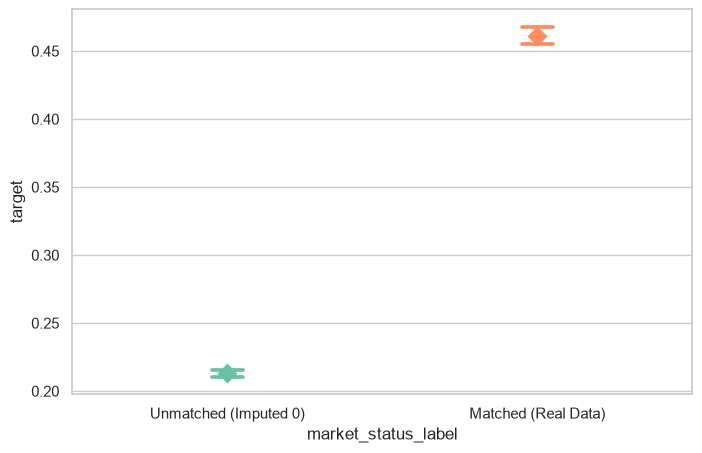

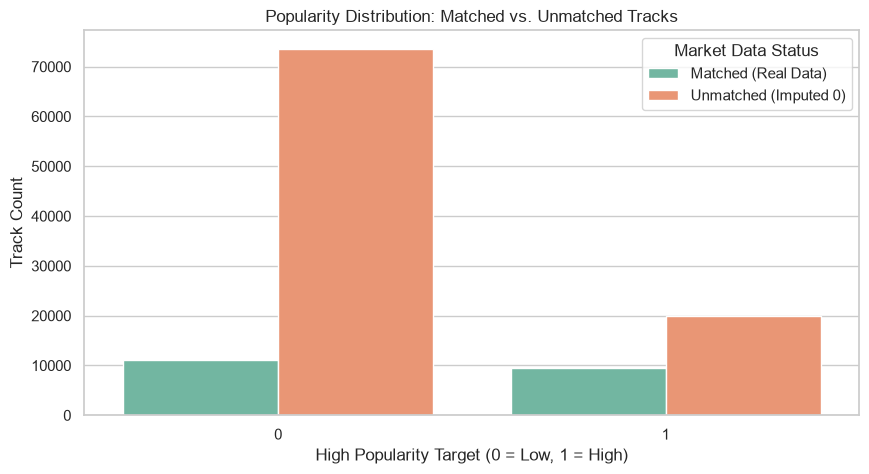

In [63]:
plt.figure(figsize=(8, 5))
ax = sns.pointplot(data=df,x='market_status_label',y='target',hue='market_status_label', palette='Set2',legend=False,capsize=0.1,
                   markers='D',markersize=8)

plt.figure(figsize=(10, 5))
df['market_status_label'] = df['has_market_data'].map({1: 'Matched (Real Data)', 0: 'Unmatched (Imputed 0)'})
sns.countplot(data=df, x='target', hue='market_status_label', palette='Set2')
plt.title('Popularity Distribution: Matched vs. Unmatched Tracks')
plt.xlabel('High Popularity Target (0 = Low, 1 = High)')
plt.ylabel('Track Count')
plt.legend(title='Market Data Status')
plt.show()

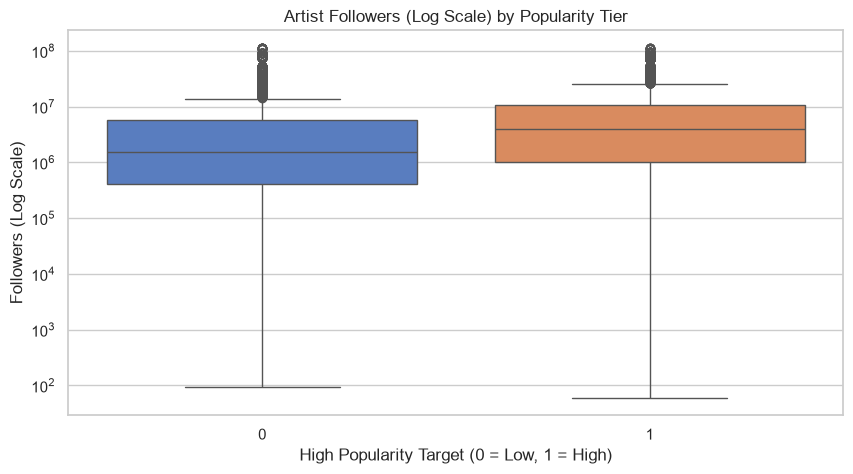

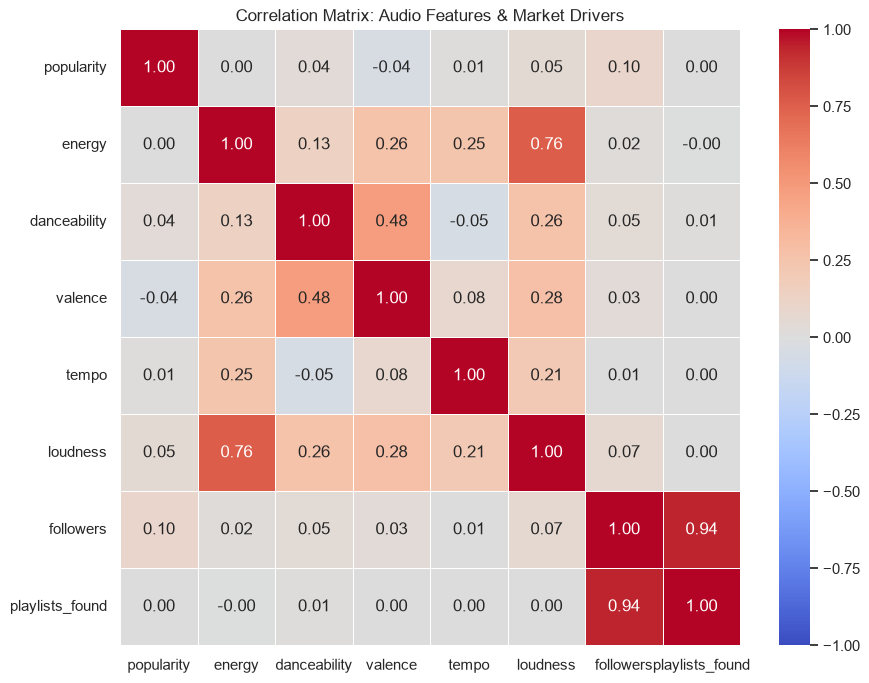

In [64]:
plt.figure(figsize=(10, 5))
matched_df = df[df['followers'] > 0]
sns.boxplot(x='target', y='followers', hue='target', data=matched_df, palette='muted', legend=False)
plt.yscale('log')
plt.title('Artist Followers (Log Scale) by Popularity Tier')
plt.xlabel('High Popularity Target (0 = Low, 1 = High)')
plt.ylabel('Followers (Log Scale)')
plt.show()

# 3. Correlation Heatmap (with safe numeric coercion)
plt.figure(figsize=(10, 8))
num_cols = ['popularity', 'energy', 'danceability', 'valence', 'tempo', 'loudness', 'followers', 'playlists_found']
existing_num_cols = [col for col in num_cols if col in df.columns]

corr_df = df[existing_num_cols].copy()
for col in existing_num_cols:
    corr_df[col] = pd.to_numeric(corr_df[col], errors='coerce')

corr = corr_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix: Audio Features & Market Drivers')
plt.show()

In [65]:
print(corr)
mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
strongest_pairs = corr.where(mask).unstack().dropna()
top_correlation = strongest_pairs.abs().sort_values(ascending=False).head(1)
top_pair_name = top_correlation.index[0]
actual_value = strongest_pairs[top_pair_name]
print(f"The two features with the biggest correlation: {top_pair_name[0]} and {top_pair_name[1]}")
print(f"Correlation value being: {actual_value:.2f}")

                 popularity    energy  danceability   valence     tempo  \
popularity         1.000000  0.001056      0.035448 -0.040534  0.013205   
energy             0.001056  1.000000      0.134325  0.258934  0.247851   
danceability       0.035448  0.134325      1.000000  0.477341 -0.050450   
valence           -0.040534  0.258934      0.477341  1.000000  0.078273   
tempo              0.013205  0.247851     -0.050450  0.078273  1.000000   
loudness           0.050423  0.761690      0.259077  0.279848  0.212446   
followers          0.100459  0.023342      0.046846  0.034085  0.006722   
playlists_found    0.000610 -0.001981      0.010586  0.003454  0.001270   

                 loudness  followers  playlists_found  
popularity       0.050423   0.100459         0.000610  
energy           0.761690   0.023342        -0.001981  
danceability     0.259077   0.046846         0.010586  
valence          0.279848   0.034085         0.003454  
tempo            0.212446   0.006722        

In [66]:
# Stratified train/test split to preserve class balance
df_train, df_val = train_test_split(df, test_size=0.2, random_state=42, stratify=df['target'])

y_train = df_train['target'].values
y_val = df_val['target'].values

train_dicts = df_train[extended_features].to_dict(orient='records')
val_dicts = df_val[extended_features].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"X_train feature matrix shape: {X_train.shape}")

X_train feature matrix shape: (91200, 352)


In [67]:
# Calculati:on scale_pos_weight for XGBoost-train class balance
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count
print(f"Training set class balance - Low Pop (0): {neg_count}, High Pop (1): {pos_count}")
print(f"Calculated scale_pos_weight for XGBoost: {scale_pos_weight_val:.2f}\n")

# Logistic Regression 
lr_model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_prob_lr = lr_model.predict_proba(X_val_scaled)[:, 1]
print(f"Tuned Logistic Regression ROC-AUC: {roc_auc_score(y_val, y_prob_lr):.4f}")

xgb_model = XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=6, scale_pos_weight=scale_pos_weight_val,  
                          random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]
print("=" * 50)
print(f"Tuned XGBoost ROC-AUC: {roc_auc_score(y_val, y_prob_xgb):.4f}")
balanced_threshold = 0.60
y_pred_balanced = (y_prob_xgb >= balanced_threshold).astype(int)
print("=" * 50)
print(f"\nClassification Report (XGBoost with Balanced Threshold @ {balanced_threshold})")
print("=" * 50)
print(classification_report(y_val, y_pred_balanced))


Training set class balance - Low Pop (0): 67706, High Pop (1): 23494
Calculated scale_pos_weight for XGBoost: 2.88

Tuned Logistic Regression ROC-AUC: 0.8301
Tuned XGBoost ROC-AUC: 0.8321

Classification Report (XGBoost with Balanced Threshold @ 0.6)
              precision    recall  f1-score   support

           0       0.84      0.90      0.87     16927
           1       0.65      0.50      0.57      5873

    accuracy                           0.80     22800
   macro avg       0.74      0.70      0.72     22800
weighted avg       0.79      0.80      0.79     22800



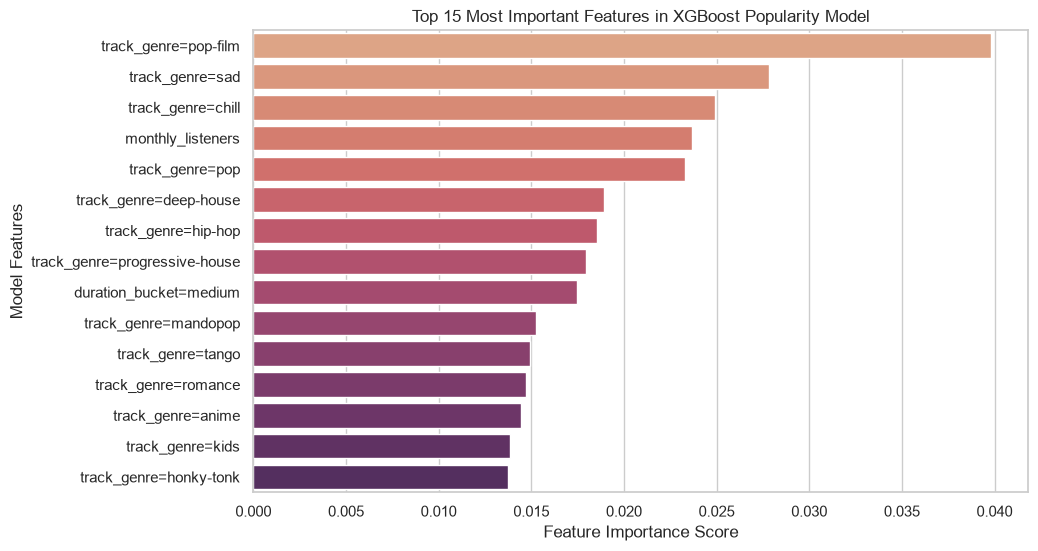

In [68]:
# Extract feature names and importances from XGBoost
feature_names = dv.get_feature_names_out()
importances = xgb_model.feature_importances_
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(15)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df, x='Importance', y='Feature', hue='Feature',palette='flare', legend=False)
plt.title('Top 15 Most Important Features in XGBoost Popularity Model')
plt.xlabel('Feature Importance Score')
plt.ylabel('Model Features')
plt.show()

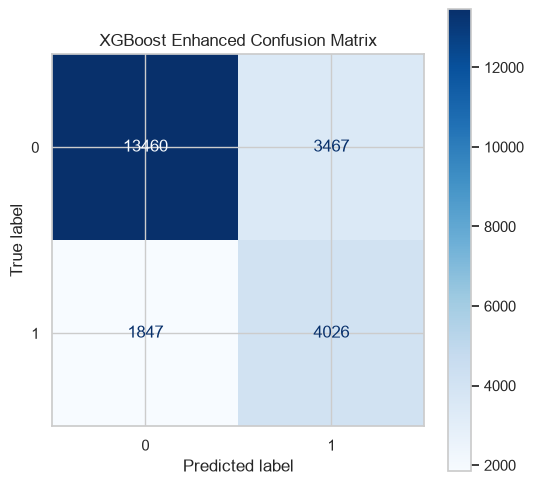

Model artifact bundle successfully saved to 'models/spotify_xgb_model.pkl'!


In [70]:
y_pred_xgb = xgb_model.predict(X_val)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_xgb, ax=ax, cmap='Blues', values_format='d')
plt.title('XGBoost Enhanced Confusion Matrix')
plt.show()
os.makedirs("models", exist_ok=True)

# Package everything into your requested dictionary artifact structur
spotify_artifact = {
    "dv": dv,
    "model": xgb_model,
    "features": extended_features,
    "target_definition": "High Popularity (Score >= 50)"
}

# Save the bundle using joblib
joblib.dump(spotify_artifact, 'models/spotify_xgb_model.pkl')
print("Model artifact bundle successfully saved to 'models/spotify_xgb_model.pkl'!")

In [71]:
artifact = joblib.load("models/spotify_xgb_model.pkl")
dv = artifact["dv"]
model = artifact["model"]
features = artifact["features"]
print(f"Artifact loaded successfully! Target definition: {artifact['target_definition']}")

# EDA for unseen tracks
print(f"Loaded {len(df_unseen)} unseen tracks for scoring.")
for col in ['followers', 'monthly_listeners', 'playlists_found']:
    if col not in df_unseen.columns:
        df_unseen[col] = 0

df_unseen['has_market_data'] = (df_unseen['followers'] > 0).astype(int)
df_unseen['followers'] = df_unseen['followers'].fillna(0)
df_unseen['monthly_listeners'] = df_unseen['monthly_listeners'].fillna(0)
df_unseen['playlists_found'] = df_unseen['playlists_found'].fillna(0)
df_unseen['major_label'] = (df_unseen['followers'] > 1000000).astype(int)
df_unseen['duration_bucket'] = pd.cut(df_unseen['duration_ms'], bins=[0, 120000, 240000, np.inf], labels=['short', 'medium', 'long']).astype(str)
df_unseen['acoustic_energy_ratio'] = df_unseen['acousticness'] / (df_unseen['energy'] + 1e-5)

unseen_dicts = df_unseen[features].to_dict(orient='records')
X_unseen = dv.transform(unseen_dicts)
probs = model.predict_proba(X_unseen)[:, 1]
tuned_threshold = 0.6
predictions = (probs >= tuned_threshold).astype(int)
df_unseen['hit_probability'] = probs
df_unseen['predicted_high_popularity'] = predictions
print("\n--- Sample Prediction Results ---")
output_cols = [col for col in ['track_name', 'artists', 'hit_probability', 'predicted_high_popularity'] if col in df_unseen.columns]
print(df_unseen[output_cols].head(10))
df_unseen.to_csv("data/scored_unseen_tracks.csv", index=False)
print("\nScored results successfully saved to 'data/scored_unseen_tracks.csv'!")

Artifact loaded successfully! Target definition: High Popularity (Score >= 50)
Loaded 114000 unseen tracks for scoring.

--- Sample Prediction Results ---
                   track_name                               artists  \
0                      Comedy                           Gen Hoshino   
1            Ghost - Acoustic                          Ben Woodward   
2              To Begin Again                Ingrid Michaelson;ZAYN   
3  Can't Help Falling In Love                          Kina Grannis   
4                     Hold On                      Chord Overstreet   
5        Days I Will Remember                          Tyrone Wells   
6               Say Something  A Great Big World;Christina Aguilera   
7                   I'm Yours                            Jason Mraz   
8                       Lucky             Jason Mraz;Colbie Caillat   
9                      Hunger                        Ross Copperman   

   hit_probability  predicted_high_popularity  
0         0.431